<a href="https://colab.research.google.com/github/cristiangromero/LGRT-PIA/blob/main/Clasificacion_Calidad_Vinos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ¿Este vino es bueno? Clasificación de la calidad de vinos con Machine Learning
**Materia:** Principios de Inteligencia Artificial · **Actividad Nº 10 · Proyecto integrador de ML** · Cristian Romero

**Problema:** a partir de 11 mediciones fisicoquímicas de laboratorio (acidez, azúcar, sulfitos, alcohol, etc.) predecir si un vino será calificado como **bueno** (nota ≥ 7 sobre 10) por catadores expertos. Es un problema de **clasificación binaria supervisada**: cada vino del dataset trae la nota real asignada por los catadores.

**¿Por qué me interesa?** La calidad de un vino se define hoy con catas sensoriales, que son lentas, caras y subjetivas. Un modelo que anticipe la calidad a partir de análisis de laboratorio que la bodega **ya realiza** (por control y normativa) sirve para priorizar lotes, detectar problemas temprano en la producción y apoyar decisiones de precio. Es exactamente el tipo de problema de *gestión de recursos con datos* que trabaja la carrera.

**Datos:** *Wine Quality Data Set* — UCI Machine Learning Repository (Cortez et al., 2009). Vinos tintos y blancos de la variedad portuguesa *Vinho Verde*.

**Plan de trabajo (flujo visto en clase):**
1. Obtención de datos → 2. Limpieza → 3. EDA → 4. Preparación y división train/test → 5. Baselines simples → 6. Modelos más complejos → 7. Ajuste de hiperparámetros → 8. Evaluación final en test → 9. Bonus no supervisado (K-Means) → 10. Inferencia y conclusiones.

## FASE 1. Obtención de los datos

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("figuras", exist_ok=True)
def guardar(nombre):
    plt.savefig(f"figuras/{nombre}.png", dpi=150, bbox_inches="tight")

URL_BASE = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"
def cargar(nombre):
    # Usa la copia local si existe (carpeta data/); si no, descarga directo de UCI (Colab).
    local = os.path.join("data", nombre)
    return pd.read_csv(local if os.path.exists(local) else URL_BASE + nombre, sep=";")

tintos = cargar("winequality-red.csv")
blancos = cargar("winequality-white.csv")
print("Tintos :", tintos.shape)
print("Blancos:", blancos.shape)

Tintos : (1599, 12)
Blancos: (4898, 12)


Los dos archivos tienen las mismas 12 columnas. Se unen en un solo DataFrame y se agrega la columna `tipo` (0 = tinto, 1 = blanco), porque el tipo de vino puede influir en la calidad y en las mediciones.

In [2]:
tintos["tipo"] = 0
blancos["tipo"] = 1
vinos = pd.concat([tintos, blancos], ignore_index=True)
vinos.columns = ["acidez_fija", "acidez_volatil", "acido_citrico", "azucar_residual",
                 "cloruros", "so2_libre", "so2_total", "densidad", "pH",
                 "sulfatos", "alcohol", "calidad", "tipo"]
vinos.head()

,acidez_fija,acidez_volatil,acido_citrico,azucar_residual,cloruros,so2_libre,so2_total,densidad,pH,sulfatos,alcohol,calidad,tipo
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [3]:
vinos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   acidez_fija      6497 non-null   float64
 1   acidez_volatil   6497 non-null   float64
 2   acido_citrico    6497 non-null   float64
 3   azucar_residual  6497 non-null   float64
 4   cloruros         6497 non-null   float64
 5   so2_libre        6497 non-null   float64
 6   so2_total        6497 non-null   float64
 7   densidad         6497 non-null   float64
 8   pH               6497 non-null   float64
 9   sulfatos         6497 non-null   float64
 10  alcohol          6497 non-null   float64
 11  calidad          6497 non-null   int64  
 12  tipo             6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


**Diccionario de variables**

| Variable | Unidad | Significado |
|---|---|---|
| acidez_fija | g ácido tartárico/dm³ | Ácidos que no se evaporan (tartárico, málico) |
| acidez_volatil | g ácido acético/dm³ | Ácido acético; en exceso da sabor a vinagre |
| acido_citrico | g/dm³ | Aporta frescura |
| azucar_residual | g/dm³ | Azúcar que queda tras la fermentación |
| cloruros | g cloruro de sodio/dm³ | Sal del vino |
| so2_libre / so2_total | mg/dm³ | Dióxido de azufre (conservante) libre y total |
| densidad | g/cm³ | Depende del alcohol y el azúcar |
| pH | — | Nivel de acidez (0 a 14) |
| sulfatos | g sulfato de potasio/dm³ | Aditivo antimicrobiano |
| alcohol | % vol. | Graduación alcohólica |
| **calidad** | 0–10 | **Variable objetivo**: mediana de al menos 3 catadores |
| tipo | 0/1 | Agregada: 0 = tinto, 1 = blanco |

## FASE 2. Limpieza de datos

### 2.1 Valores faltantes y tipos de datos

In [4]:
print("Valores nulos por columna:\n", vinos.isna().sum().to_string())
print("\nTipos:", vinos.dtypes.value_counts().to_dict())

Valores nulos por columna:
 acidez_fija        0
acidez_volatil     0
acido_citrico      0
azucar_residual    0
cloruros           0
so2_libre          0
so2_total          0
densidad           0
pH                 0
sulfatos           0
alcohol            0
calidad            0
tipo               0

Tipos: {dtype('float64'): 11, dtype('int64'): 2}


No hay valores faltantes y todas las columnas son numéricas, así que **no hace falta imputar ni codificar texto**. (`tipo` ya es 0/1; al ser binaria no necesita One-Hot Encoding.)

### 2.2 Registros duplicados

In [5]:
dup = vinos.duplicated()
print(f"Filas duplicadas: {dup.sum()} de {len(vinos)} ({dup.mean():.1%})")
print(vinos[dup]["tipo"].map({0: "tinto", 1: "blanco"}).value_counts().to_string())

Filas duplicadas: 1177 de 6497 (18.1%)
tipo
blanco    937
tinto     240


In [6]:
vinos = vinos.drop_duplicates().reset_index(drop=True)
print("Tamaño luego de eliminar duplicados:", vinos.shape)

Tamaño luego de eliminar duplicados: (5320, 13)


**Decisión sobre duplicados:** aproximadamente 1 de cada 6 filas es una copia exacta de otra (las 11 mediciones y la nota idénticas). Lo más probable es que correspondan al mismo vino registrado más de una vez. Si se conservan, una copia puede caer en *train* y su gemela en *test*: el modelo "reconoce" el vino en lugar de predecirlo y las métricas salen **infladas artificialmente**. Esto es una forma de **data leakage** (fuga de datos), uno de los errores comunes vistos en clase. Por eso se eliminan **antes** de dividir los datos.

### 2.3 Valores atípicos (outliers)

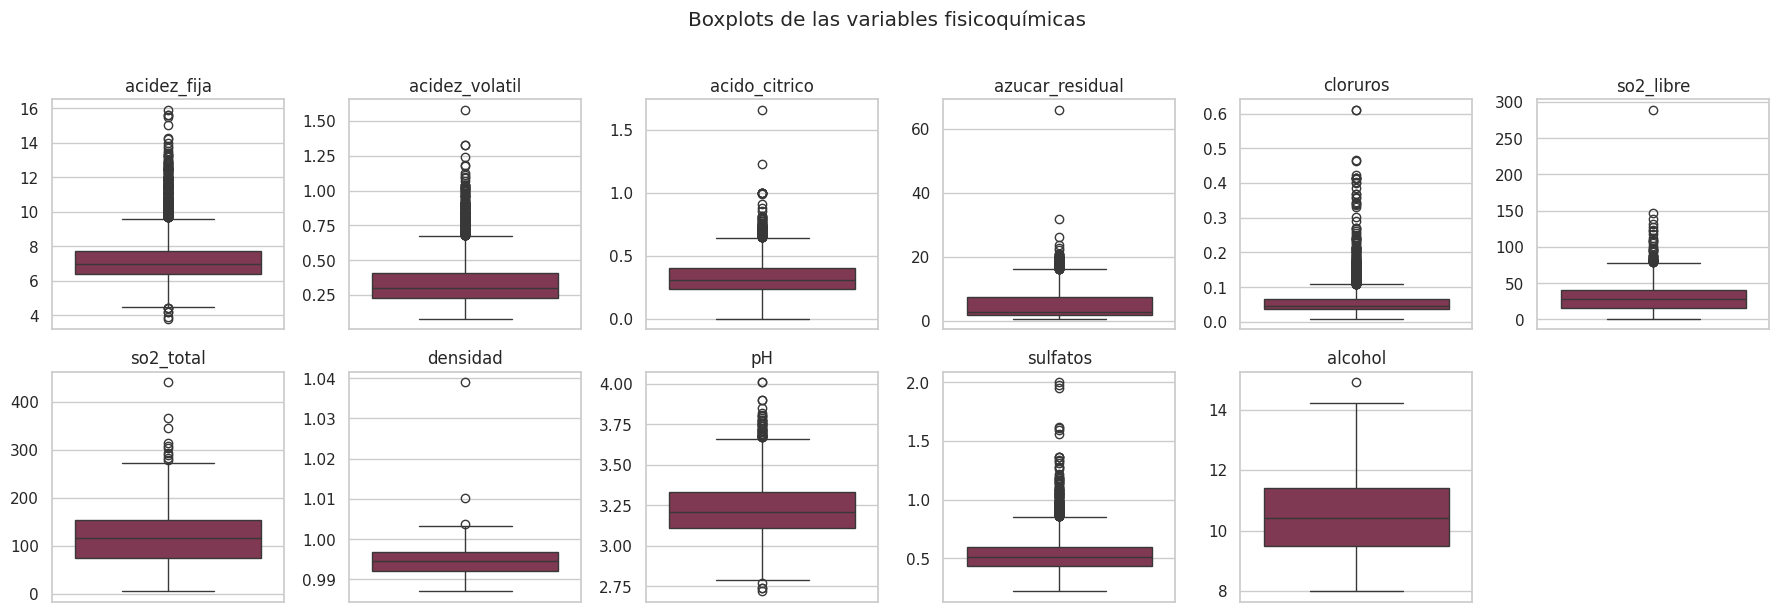

,outliers (1.5·IQR),mínimo,máximo
acidez_fija,304,3.80000,15.90000
acidez_volatil,279,0.08000,1.58000
acido_citrico,143,0.00000,1.66000
azucar_residual,141,0.60000,65.80000
cloruros,237,0.00900,0.61100
so2_libre,44,1.00000,289.00000
so2_total,10,6.00000,440.00000
densidad,3,0.98711,1.03898
pH,49,2.72000,4.01000
sulfatos,163,0.22000,2.00000


In [7]:
features = [c for c in vinos.columns if c not in ("calidad", "tipo")]
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, c in zip(axes.flat, features):
    sns.boxplot(y=vinos[c], ax=ax, color="#8c2d4f"); ax.set_title(c); ax.set_ylabel("")
axes.flat[-1].axis("off")
plt.suptitle("Boxplots de las variables fisicoquímicas", y=1.02); plt.tight_layout()
guardar("01_boxplots"); plt.show()

def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
pd.DataFrame({"outliers (1.5·IQR)": [outliers_iqr(vinos[c]) for c in features],
              "mínimo": vinos[features].min().values,
              "máximo": vinos[features].max().values}, index=features)

**Decisión sobre outliers:** todas las variables tienen valores fuera del rango 1,5·IQR, pero al revisarlos son **valores químicamente posibles** (vinos dulces con mucha azúcar, tintos con más cloruros, etc.), no errores de carga. Siguiendo el criterio aplicado en actividades anteriores —*se elimina un outlier si es un error; si es un caso real, se conserva*— se mantienen. Además:
- Los modelos basados en árboles (Árbol, Random Forest, Gradient Boosting) son **robustos** a outliers.
- Para los modelos sensibles a la escala (Regresión Logística, KNN, SVM) se aplicará **estandarización** dentro de un `Pipeline`.

## FASE 3. Análisis Exploratorio de Datos (EDA)

### 3.1 Estadística descriptiva

In [ ]:
vinos.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
acidez_fija,5320.0,7.215,1.320,3.800,6.400,7.000,7.700,15.900
acidez_volatil,5320.0,0.344,0.168,0.080,0.230,0.300,0.410,1.580
acido_citrico,5320.0,0.318,0.147,0.000,0.240,0.310,0.400,1.660
azucar_residual,5320.0,5.048,4.500,0.600,1.800,2.700,7.500,65.800
cloruros,5320.0,0.057,0.037,0.009,0.038,0.047,0.066,0.611
so2_libre,5320.0,30.037,17.805,1.000,16.000,28.000,41.000,289.000
so2_total,5320.0,114.109,56.774,6.000,74.000,116.000,153.250,440.000
densidad,5320.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,5320.0,3.225,0.160,2.720,3.110,3.210,3.330,4.010
sulfatos,5320.0,0.533,0.150,0.220,0.430,0.510,0.600,2.000


### 3.2 Variable objetivo: `calidad`

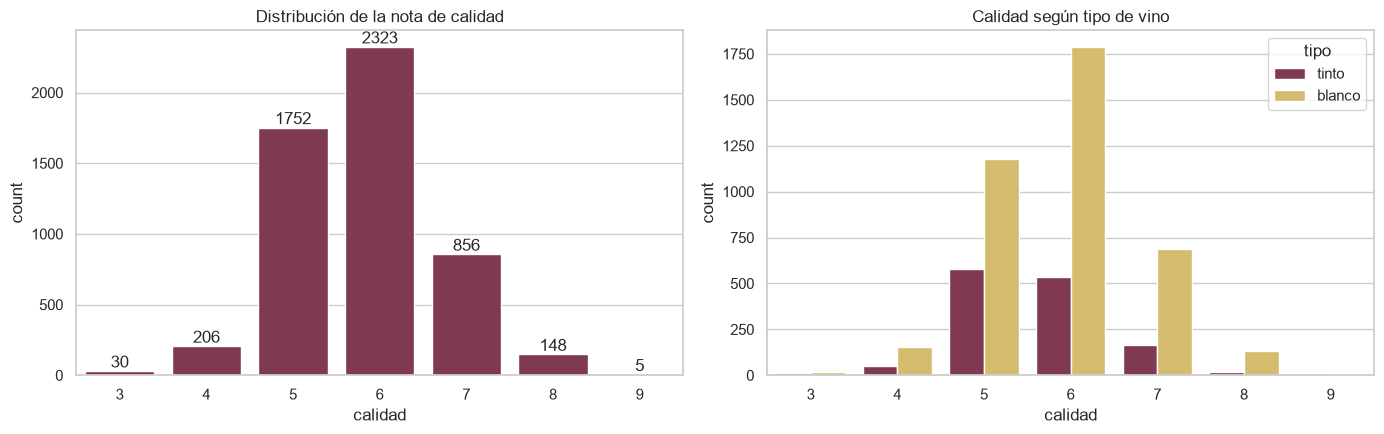

calidad
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
orden = sorted(vinos["calidad"].unique())
sns.countplot(x="calidad", data=vinos, ax=ax[0], color="#8c2d4f", order=orden)
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax[0].set_title("Distribución de la nota de calidad")
sns.countplot(x="calidad", hue=vinos["tipo"].map({0: "tinto", 1: "blanco"}), data=vinos, ax=ax[1],
              palette=["#8c2d4f", "#e6c35c"], order=orden)
ax[1].set_title("Calidad según tipo de vino"); ax[1].legend(title="tipo")
plt.tight_layout(); guardar("02_calidad"); plt.show()
print(vinos["calidad"].value_counts().sort_index().to_string())

**Observaciones:**
- La nota va de 3 a 9 (nunca se usaron los extremos 0–2 ni 10) y se concentra en **5 y 6**: la mayoría de los vinos son "normales".
- Las clases extremas (3, 4, 8, 9) tienen muy pocos ejemplos: predecir la nota exacta (7 clases) sería muy difícil con tan pocos casos en los extremos.
- **Reformulación del problema:** la pregunta de negocio relevante es *"¿este lote es de calidad premium?"*. Se crea la variable binaria **`bueno` = 1 si calidad ≥ 7**, 0 en caso contrario.

In [ ]:
vinos["bueno"] = (vinos["calidad"] >= 7).astype(int)
prop = vinos["bueno"].value_counts(normalize=True)
print(f"Vinos buenos (≥7): {vinos['bueno'].sum()} ({prop[1]:.1%})")
print(f"Vinos no buenos  : {(1 - vinos['bueno']).sum()} ({prop[0]:.1%})")
print("\nProporción de buenos por tipo:")
print(vinos.groupby(vinos["tipo"].map({0: "tinto", 1: "blanco"}))["bueno"].mean().round(3).to_string())

Vinos buenos (≥7): 1009 (19.0%)
Vinos no buenos  : 4311 (81.0%)

Proporción de buenos por tipo:
tipo
blanco    0.208
tinto     0.135


**Clases desbalanceadas:** solo ≈ 1 de cada 5 vinos es "bueno". Esto tiene dos consecuencias importantes que se tendrán en cuenta:
1. La **accuracy es engañosa**: un modelo que diga siempre "no bueno" acertaría ≈ 80 % sin aprender nada.
2. Se usarán métricas adecuadas para desbalance: **F1-Score** (métrica principal), **Precision**, **Recall** y **ROC-AUC**, junto con división **estratificada** y la opción `class_weight="balanced"`.

### 3.3 Distribución de cada variable

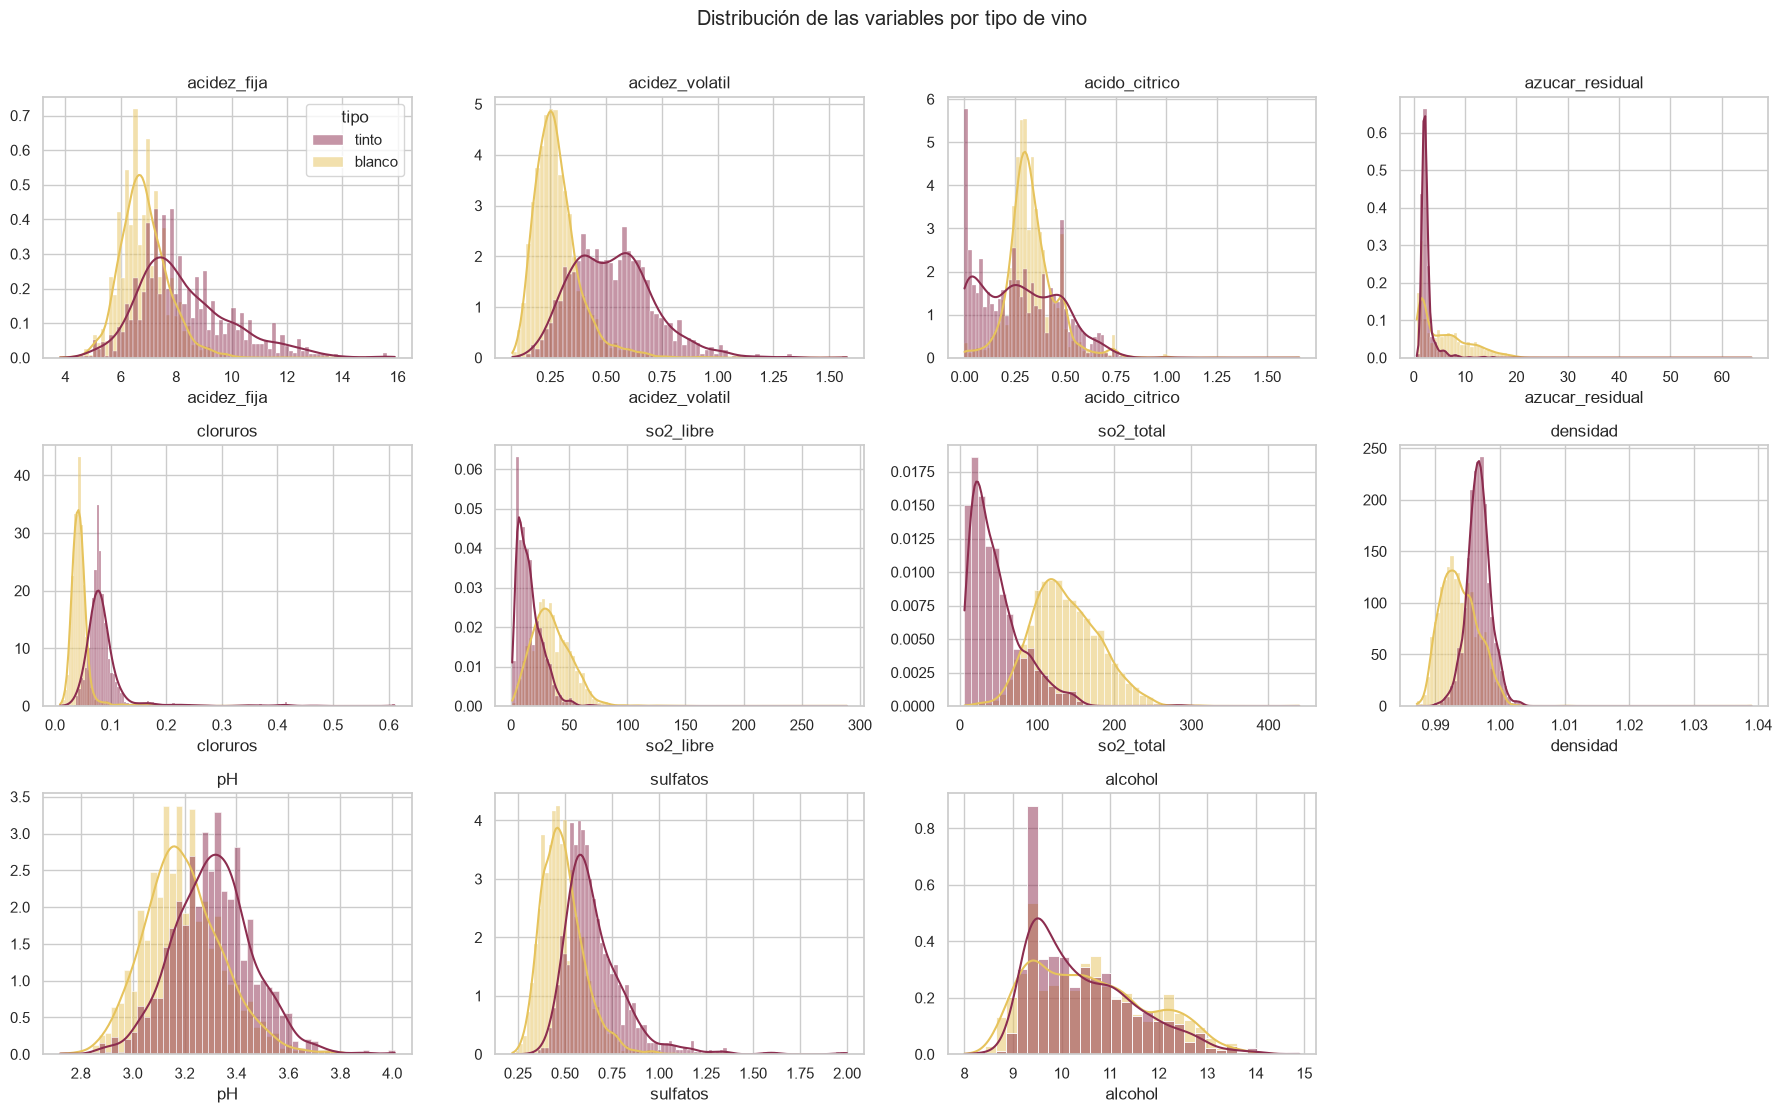

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.flat, features):
    sns.histplot(data=vinos, x=c, hue=vinos["tipo"].map({0: "tinto", 1: "blanco"}), kde=True, ax=ax,
                 palette=["#8c2d4f", "#e6c35c"], stat="density", common_norm=False, legend=(c == features[0]))
    ax.set_title(c); ax.set_ylabel("")
axes.flat[-1].axis("off")
plt.suptitle("Distribución de las variables por tipo de vino", y=1.01); plt.tight_layout()
guardar("03_histogramas"); plt.show()

**Observaciones:**
- Varias variables tienen **asimetría a la derecha** (azúcar residual, cloruros, SO₂, sulfatos): muchos valores bajos y una cola de valores altos.
- **Tintos y blancos son químicamente distintos**: los blancos tienen mucho más SO₂ total y azúcar; los tintos más acidez volátil, cloruros y sulfatos. Por eso conviene conservar la variable `tipo` como predictora.

### 3.4 ¿Qué diferencia a un vino bueno de uno que no lo es?

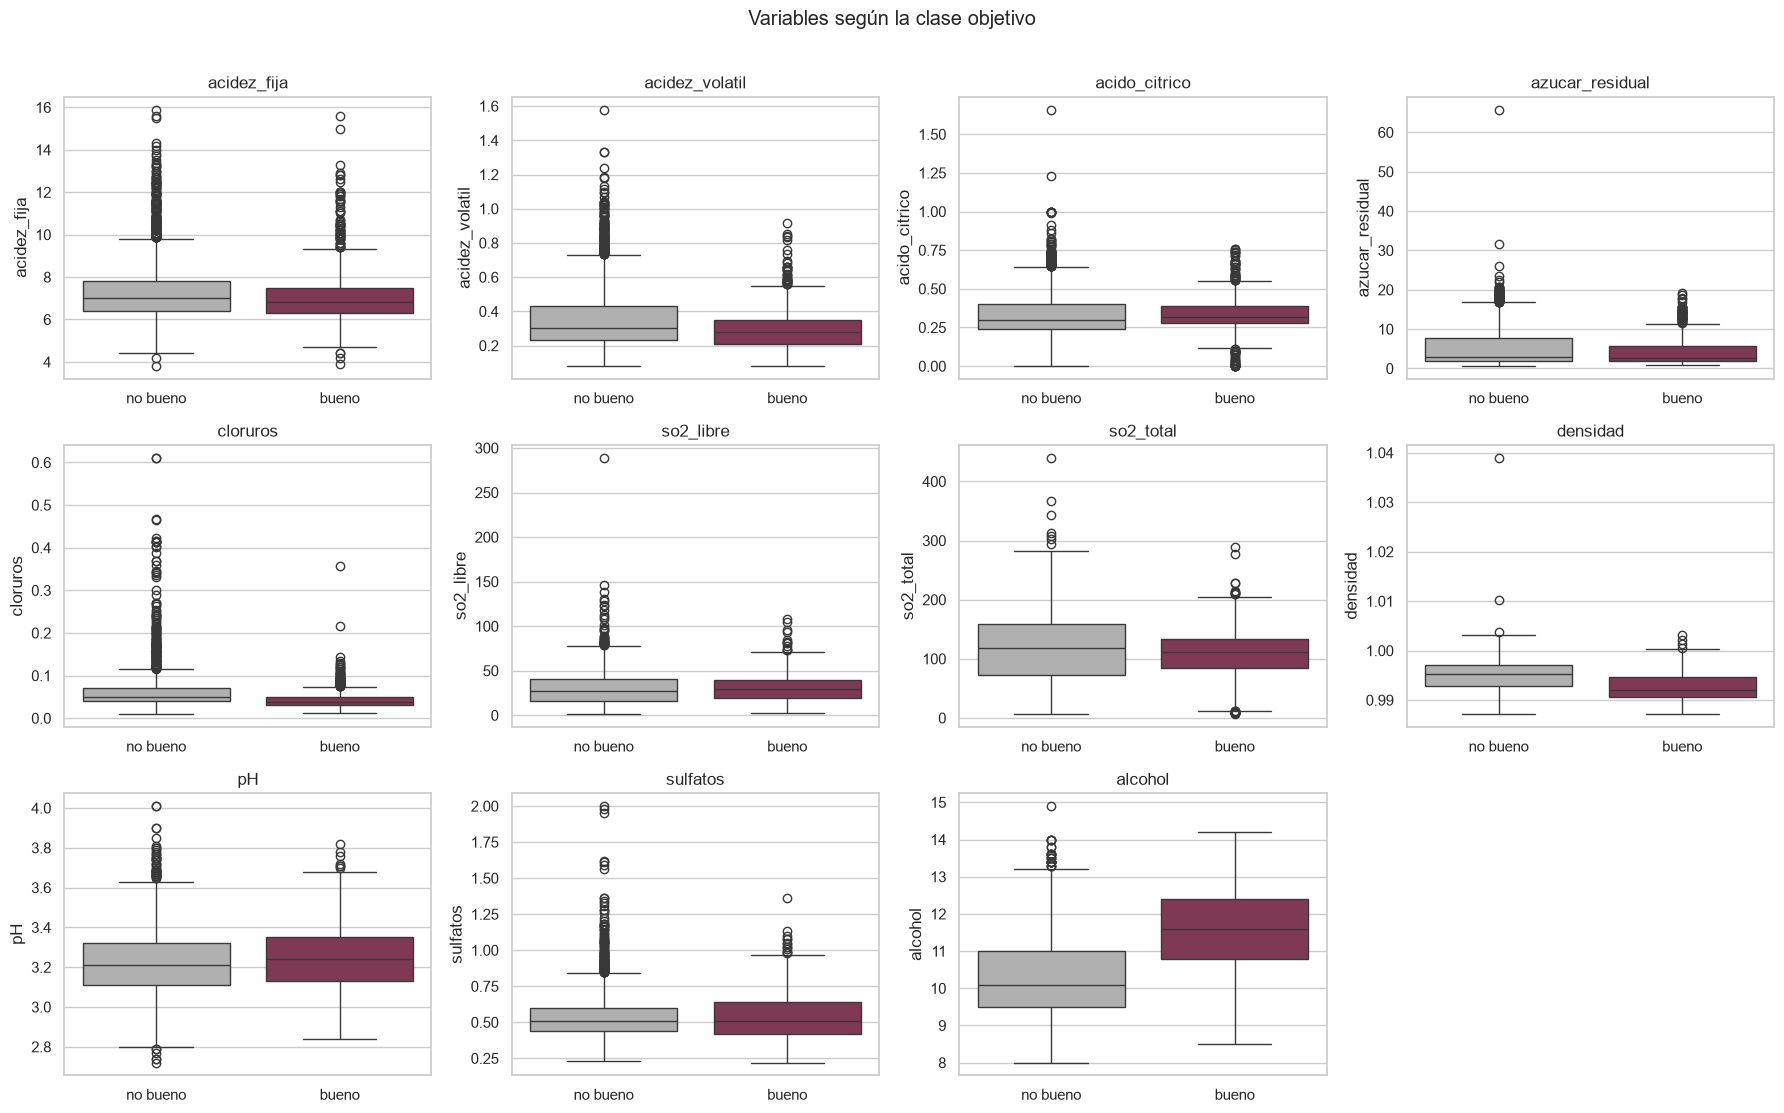

,mediana no bueno,mediana bueno,diferencia %
cloruros,0.0490,0.038,-22.4
acidez_volatil,0.3000,0.280,-6.7
so2_total,118.0000,112.000,-5.1
azucar_residual,2.8000,2.700,-3.6
acidez_fija,7.0000,6.800,-2.9
densidad,0.9952,0.992,-0.3
sulfatos,0.5100,0.510,0.0
pH,3.2100,3.240,0.9
acido_citrico,0.3000,0.320,6.7
so2_libre,27.0000,30.000,11.1


In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.flat, features):
    sns.boxplot(data=vinos, x="bueno", y=c, ax=ax, palette=["#b0b0b0", "#8c2d4f"])
    ax.set_title(c); ax.set_xlabel(""); ax.set_xticklabels(["no bueno", "bueno"])
axes.flat[-1].axis("off")
plt.suptitle("Variables según la clase objetivo", y=1.01); plt.tight_layout()
guardar("04_boxplots_clase"); plt.show()

comp = vinos.groupby("bueno")[features].median().T
comp.columns = ["mediana no bueno", "mediana bueno"]
comp["diferencia %"] = ((comp["mediana bueno"] / comp["mediana no bueno"] - 1) * 100).round(1)
comp.sort_values("diferencia %")

### 3.5 Correlaciones

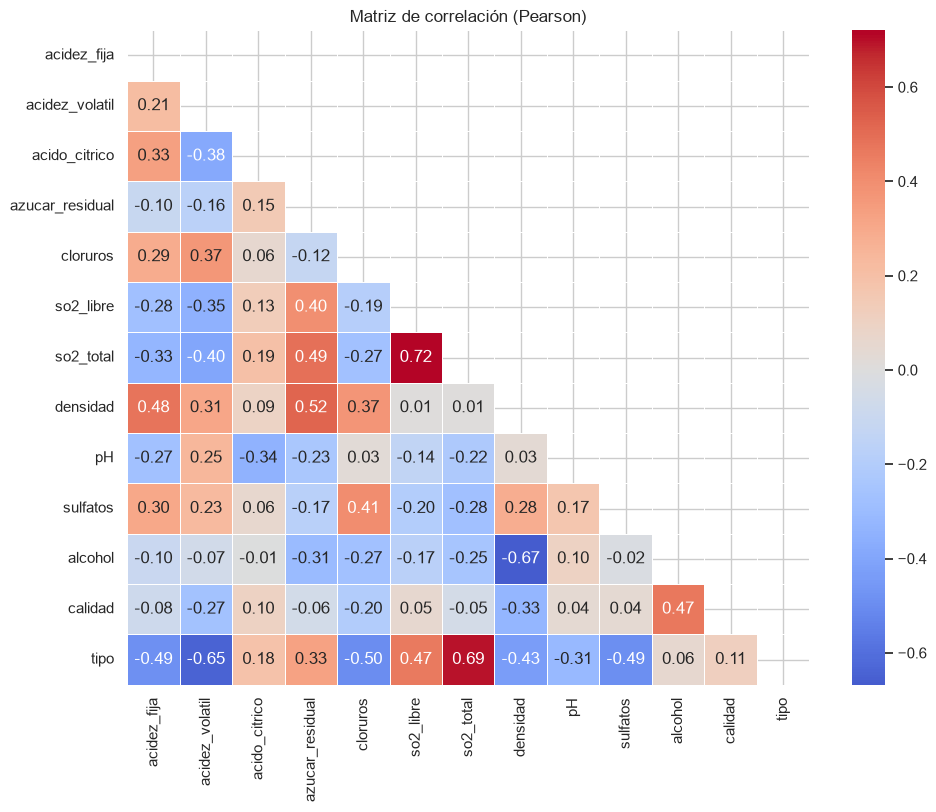

densidad          -0.326434
acidez_volatil    -0.265205
cloruros          -0.202137
acidez_fija       -0.080092
azucar_residual   -0.056830
so2_total         -0.050296
pH                 0.039733
sulfatos           0.041884
so2_libre          0.054002
acido_citrico      0.097954
tipo               0.114809
alcohol            0.469422
Name: calidad, dtype: float64

In [ ]:
corr = vinos.drop(columns="bueno").corr()
plt.figure(figsize=(11, 8.5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Matriz de correlación (Pearson)"); guardar("05_correlacion"); plt.show()
corr["calidad"].drop("calidad").sort_values()

**Observaciones del análisis de correlación:**
- **`alcohol`** es, por lejos, la variable más relacionada con la calidad (correlación positiva ≈ 0,47): a mayor graduación, mejor nota.
- **`densidad`** (−0,33) y **`acidez_volatil`** (−0,27) se relacionan negativamente: el exceso de ácido acético "avinagra" el vino.
- **Multicolinealidad:** `densidad` está muy correlacionada con `alcohol` (≈ −0,69) y con `azucar_residual`. Es lógico (el alcohol es menos denso que el agua). Para los árboles no es un problema; en la regresión logística hace que los coeficientes sean menos interpretables.
- `so2_libre` y `so2_total` también están muy correlacionadas entre sí (≈ 0,72).
- Ninguna variable por sí sola explica la calidad: las correlaciones son moderadas o bajas → se espera que **modelos no lineales**, que combinan variables, funcionen mejor.

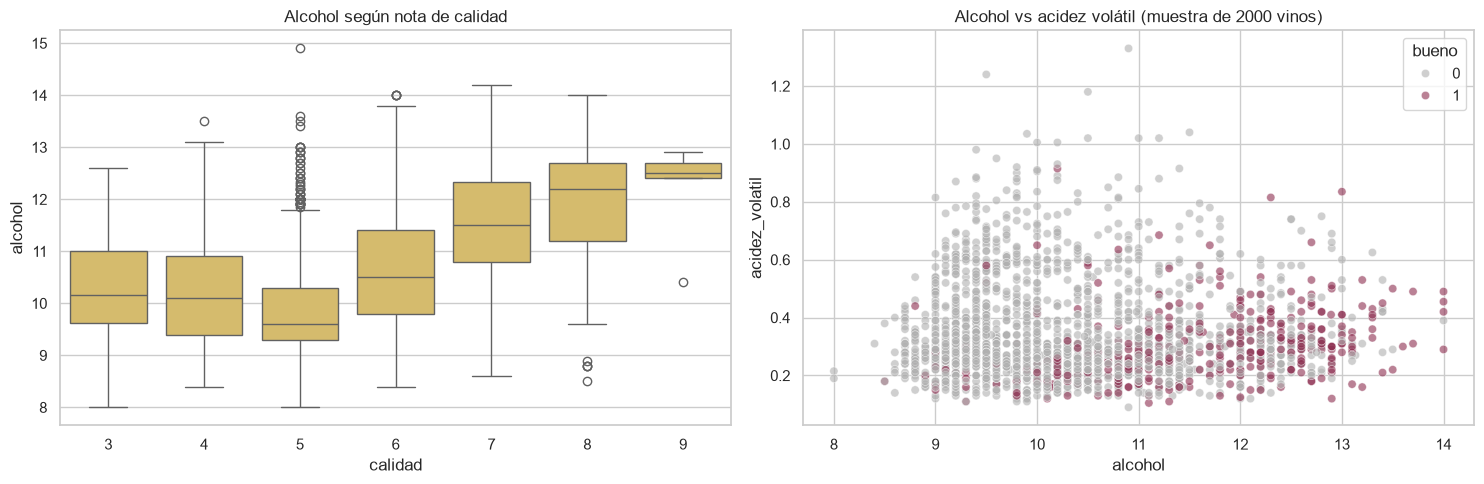

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=vinos, x="calidad", y="alcohol", ax=ax[0], color="#e6c35c")
ax[0].set_title("Alcohol según nota de calidad")
sns.scatterplot(data=vinos.sample(2000, random_state=1), x="alcohol", y="acidez_volatil",
                hue="bueno", palette=["#b0b0b0", "#8c2d4f"], alpha=.6, ax=ax[1])
ax[1].set_title("Alcohol vs acidez volátil (muestra de 2000 vinos)")
plt.tight_layout(); guardar("06_alcohol"); plt.show()

**Conclusiones del EDA (hipótesis para el modelado):**
1. El alcohol crece de forma casi escalonada con la nota: es el mejor predictor individual.
2. En el gráfico de dispersión, los vinos buenos se concentran en la zona de **alcohol alto y acidez volátil baja**, pero hay mucha superposición: **no existe una frontera lineal limpia** entre clases.
3. El problema es desbalanceado (≈ 19 % positivos) y con relaciones no lineales → candidatos naturales: **Random Forest** y **Gradient Boosting**, comparados contra baselines simples.

## FASE 4. Preparación y división train / test

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

X = vinos.drop(columns=["calidad", "bueno"])   # 11 variables químicas + tipo
y = vinos["bueno"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, f"- buenos {y_train.mean():.1%}")
print("Test :", X_test.shape, f"- buenos {y_test.mean():.1%}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
METRICAS = ["accuracy", "precision", "recall", "f1", "roc_auc"]

Train: (4256, 12) - buenos 19.0%
Test : (1064, 12) - buenos 19.0%


- Se excluye `calidad` de X porque **es** la respuesta (usarla sería data leakage).
- **80 % / 20 %** con `stratify=y` para que ambos conjuntos tengan la misma proporción de vinos buenos, y `random_state=42` para que la división sea reproducible.
- El **test se guarda bajo llave** hasta el final. Para comparar modelos y elegir hiperparámetros se usa **validación cruzada estratificada de 5 folds** sobre el conjunto de entrenamiento (consejo de la clase: *nunca confiar en un único split*).
- Escalado: se aplica `StandardScaler` **dentro de un Pipeline**, así la media y el desvío se calculan solo con los datos de entrenamiento de cada fold.

## FASE 5. Modelos baseline (simples)

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

resultados = {}
def evaluar(nombre, modelo):
    s = cross_validate(modelo, X_train, y_train, cv=cv, scoring=METRICAS, return_train_score=True, n_jobs=-1)
    resultados[nombre] = {m: s[f"test_{m}"].mean() for m in METRICAS}
    resultados[nombre]["f1_train"] = s["train_f1"].mean()
    r = resultados[nombre]
    print(f"{nombre:28s} acc={r['accuracy']:.3f}  prec={r['precision']:.3f}  rec={r['recall']:.3f}  "
          f"F1={r['f1']:.3f}  AUC={r['roc_auc']:.3f}  | F1 train={r['f1_train']:.3f}")

evaluar("0. Dummy (clase mayoritaria)", DummyClassifier(strategy="most_frequent"))
evaluar("1. Regresión Logística", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))
evaluar("2. Reg. Logística balanceada", make_pipeline(StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced")))
evaluar("3. Árbol (sin límites)", DecisionTreeClassifier(random_state=42))
evaluar("4. Árbol (max_depth=5)", DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42))

0. Dummy (clase mayoritaria) acc=0.810  prec=0.000  rec=0.000  F1=0.000  AUC=0.500  | F1 train=0.000


1. Regresión Logística       acc=0.828  prec=0.591  rec=0.309  F1=0.404  AUC=0.831  | F1 train=0.403


2. Reg. Logística balanceada acc=0.738  prec=0.403  rec=0.786  F1=0.533  AUC=0.831  | F1 train=0.539


3. Árbol (sin límites)       acc=0.771  prec=0.405  rec=0.442  F1=0.422  AUC=0.645  | F1 train=1.000


4. Árbol (max_depth=5)       acc=0.815  prec=0.525  rec=0.265  F1=0.345  AUC=0.784  | F1 train=0.456


**Lectura de los baselines:**
- **Dummy**: ≈ 81 % de accuracy pero **F1 = 0**: nunca detecta un vino bueno. Confirma que la accuracy sola no sirve en este problema; es el "piso" a superar.
- **Regresión Logística** (baseline lineal estándar para clasificación): AUC ≈ 0,80, es decir, ordena bastante bien los vinos, pero con el umbral por defecto (0,5) es muy conservadora y detecta pocos buenos (recall bajo). Con **`class_weight="balanced"`** el recall sube mucho a costa de precisión, y el F1 mejora.
- **Árbol sin límites**: F1 en train = 1,000 y mucho menor en validación → **overfitting** clásico (memoriza los datos). Limitando la profundidad (`max_depth=5`, `min_samples_leaf=10`) el sobreajuste baja, pero el modelo queda demasiado simple.
- Conclusión: el baseline a batir es la **Regresión Logística balanceada**. Como el EDA mostró relaciones no lineales, se justifica **iterar con modelos más complejos**.

## FASE 6. Iteración con modelos más complejos

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

evaluar("5. KNN (k=15)", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)))
evaluar("6. SVM (kernel RBF)", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced")))
evaluar("7. Random Forest", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))
evaluar("8. Random Forest balanceado", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
        min_samples_leaf=2, random_state=42, n_jobs=-1))
evaluar("9. Gradient Boosting", HistGradientBoostingClassifier(random_state=42))
evaluar("10. Gradient Boosting balanceado", HistGradientBoostingClassifier(class_weight="balanced", random_state=42))

5. KNN (k=15)                acc=0.829  prec=0.589  rec=0.336  F1=0.427  AUC=0.818  | F1 train=0.494


6. SVM (kernel RBF)          acc=0.746  prec=0.412  rec=0.803  F1=0.545  AUC=0.844  | F1 train=0.582


7. Random Forest             acc=0.842  prec=0.657  rec=0.351  F1=0.456  AUC=0.844  | F1 train=1.000


8. Random Forest balanceado  acc=0.844  prec=0.631  rec=0.436  F1=0.515  AUC=0.849  | F1 train=0.993


9. Gradient Boosting         acc=0.836  prec=0.605  rec=0.400  F1=0.481  AUC=0.840  | F1 train=0.966


10. Gradient Boosting balanceado acc=0.808  prec=0.495  rec=0.633  F1=0.555  AUC=0.843  | F1 train=0.892


,Accuracy,Precision,Recall,F1,ROC-AUC,F1 train
0. Dummy (clase mayoritaria),0.810,0.000,0.000,0.000,0.500,0.000
1. Regresión Logística,0.828,0.591,0.309,0.404,0.831,0.403
2. Reg. Logística balanceada,0.738,0.403,0.786,0.533,0.831,0.539
3. Árbol (sin límites),0.771,0.405,0.442,0.422,0.645,1.000
4. Árbol (max_depth=5),0.815,0.525,0.265,0.345,0.784,0.456
5. KNN (k=15),0.829,0.589,0.336,0.427,0.818,0.494
6. SVM (kernel RBF),0.746,0.412,0.803,0.545,0.844,0.582
7. Random Forest,0.842,0.657,0.351,0.456,0.844,1.000
8. Random Forest balanceado,0.844,0.631,0.436,0.515,0.849,0.993
9. Gradient Boosting,0.836,0.605,0.400,0.481,0.840,0.966


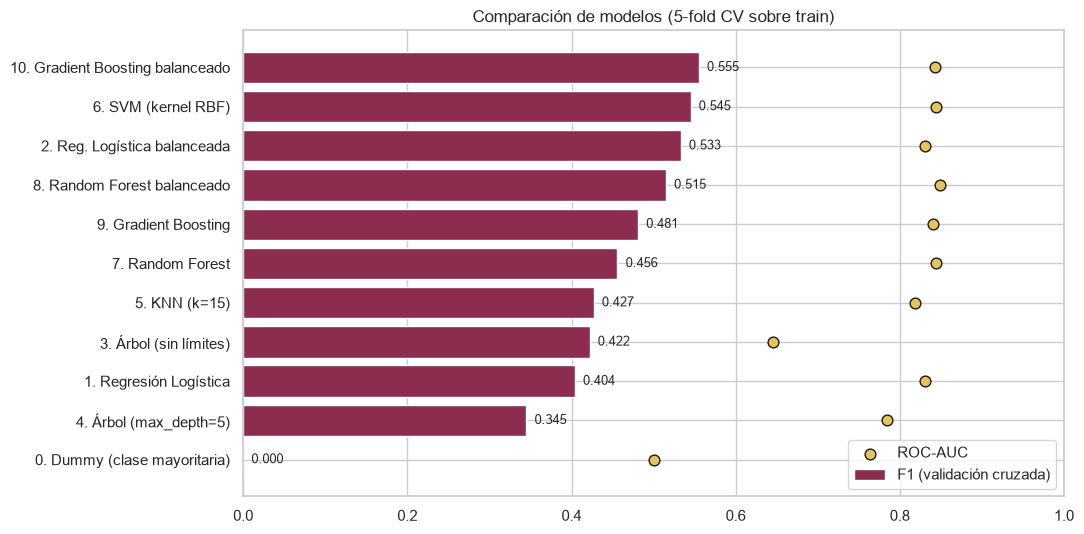

In [ ]:
tabla = pd.DataFrame(resultados).T.round(3)
tabla.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "F1 train"]
display(tabla)

fig, ax = plt.subplots(figsize=(11, 5.5))
t = tabla.sort_values("F1")
ax.barh(t.index, t["F1"], color="#8c2d4f", label="F1 (validación cruzada)")
ax.scatter(t["ROC-AUC"], t.index, color="#e6c35c", edgecolor="k", zorder=3, s=60, label="ROC-AUC")
for i, v in enumerate(t["F1"]): ax.text(v + .01, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1); ax.set_title("Comparación de modelos (5-fold CV sobre train)"); ax.legend(loc="lower right")
plt.tight_layout(); guardar("07_comparacion_modelos"); plt.show()

**Análisis de la comparación:**
- **KNN** y **SVM** (que requieren estandarización) superan a la regresión logística en AUC, confirmando que hay estructura no lineal. El SVM con `class_weight="balanced"` tiene muy buen recall pero precisión baja.
- Los **ensembles de árboles** (Random Forest y Gradient Boosting) son los mejores en F1 y en ROC-AUC, tal como anticipa la guía de la clase para *datos tabulares*.
- El **Random Forest balanceado** obtiene el mejor equilibrio entre precision y recall. Su F1 en train es muy alto (los árboles de un bosque crecen profundos), pero lo importante es que el rendimiento en validación es el mejor de todos: el promedio de muchos árboles diversos generaliza mejor que un árbol solo.
- Se seleccionan **Random Forest** y **Gradient Boosting** para el ajuste fino.

## FASE 7. Ajuste de hiperparámetros (Grid Search + validación cruzada)

In [ ]:
from sklearn.model_selection import GridSearchCV

grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=42, n_jobs=-1),
    param_grid={"max_depth": [None, 20, 12],
                "min_samples_leaf": [1, 2, 4],
                "max_features": ["sqrt", 0.5]},
    scoring="f1", cv=cv, n_jobs=-1)
grid_rf.fit(X_train, y_train)
print("Random Forest - mejores parámetros:", grid_rf.best_params_)
print(f"Random Forest - F1 CV: {grid_rf.best_score_:.3f}")

grid_gb = GridSearchCV(
    HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    param_grid={"learning_rate": [0.05, 0.1],
                "max_depth": [None, 6],
                "max_iter": [200, 400],
                "min_samples_leaf": [10, 20]},
    scoring="f1", cv=cv, n_jobs=-1)
grid_gb.fit(X_train, y_train)
print("\nGradient Boosting - mejores parámetros:", grid_gb.best_params_)
print(f"Gradient Boosting - F1 CV: {grid_gb.best_score_:.3f}")

Random Forest - mejores parámetros: {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 4}
Random Forest - F1 CV: 0.559



Gradient Boosting - mejores parámetros: {'learning_rate': 0.05, 'max_depth': 6, 'max_iter': 200, 'min_samples_leaf': 20}
Gradient Boosting - F1 CV: 0.554


### 7.1 Ajuste del umbral de decisión

Por defecto un clasificador dice "bueno" si la probabilidad es ≥ 0,5. Con clases desbalanceadas ese umbral no siempre es el óptimo. Se busca el umbral que maximiza el F1 usando **predicciones fuera de fold** (*out-of-fold*) del conjunto de entrenamiento, para no tocar el test.

Modelo seleccionado: Random Forest


F1 out-of-fold con umbral 0.50: 0.559
Umbral óptimo: 0.46 -> F1 out-of-fold: 0.562


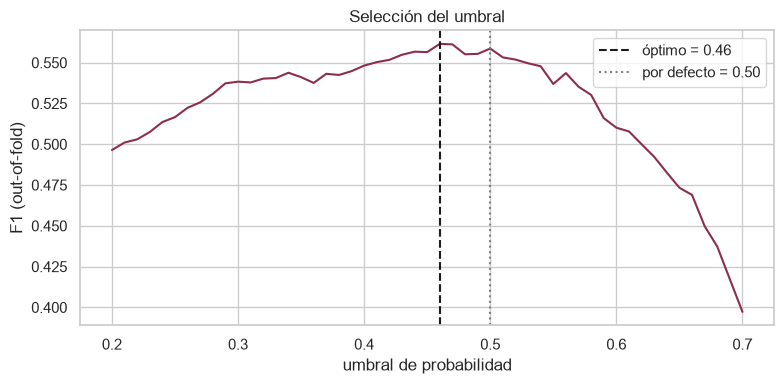

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, precision_recall_curve

mejor_nombre, mejor_grid = max([("Random Forest", grid_rf), ("Gradient Boosting", grid_gb)],
                               key=lambda t: t[1].best_score_)
print("Modelo seleccionado:", mejor_nombre)
modelo_final = mejor_grid.best_estimator_

proba_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
umbrales = np.arange(0.20, 0.71, 0.01)
f1s = [f1_score(y_train, proba_oof >= u) for u in umbrales]
umbral = float(umbrales[int(np.argmax(f1s))])
print(f"F1 out-of-fold con umbral 0.50: {f1_score(y_train, proba_oof >= 0.5):.3f}")
print(f"Umbral óptimo: {umbral:.2f} -> F1 out-of-fold: {max(f1s):.3f}")

plt.figure(figsize=(8, 4))
plt.plot(umbrales, f1s, color="#8c2d4f"); plt.axvline(umbral, ls="--", color="k", label=f"óptimo = {umbral:.2f}")
plt.axvline(0.5, ls=":", color="gray", label="por defecto = 0.50")
plt.xlabel("umbral de probabilidad"); plt.ylabel("F1 (out-of-fold)"); plt.legend(); plt.title("Selección del umbral")
plt.tight_layout(); guardar("08_umbral"); plt.show()

## FASE 8. Evaluación final en el conjunto de test

Recién ahora se usa el 20 % reservado, una sola vez, para estimar cómo funcionará el modelo con vinos nuevos.

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score)

modelo_final.fit(X_train, y_train)
proba_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= umbral).astype(int)

# Baseline (Regresión Logística balanceada) evaluado en el mismo test para comparar
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")).fit(X_train, y_train)
proba_base = baseline.predict_proba(X_test)[:, 1]; pred_base = baseline.predict(X_test)

def fila(y_true, pred, proba):
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, proba)}
final = pd.DataFrame({"Baseline: Reg. Logística balanceada": fila(y_test, pred_base, proba_base),
                      f"Final: {mejor_nombre} (umbral {umbral:.2f})": fila(y_test, pred_test, proba_test)}).T.round(3)
display(final)
print(classification_report(y_test, pred_test, target_names=["no bueno", "bueno"], digits=3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline: Reg. Logística balanceada,0.731,0.395,0.782,0.525,0.817
Final: Random Forest (umbral 0.46),0.825,0.529,0.723,0.611,0.869


              precision    recall  f1-score   support

    no bueno      0.929     0.849     0.887       862
       bueno      0.529     0.723     0.611       202

    accuracy                          0.825      1064
   macro avg      0.729     0.786     0.749      1064
weighted avg      0.853     0.825     0.835      1064



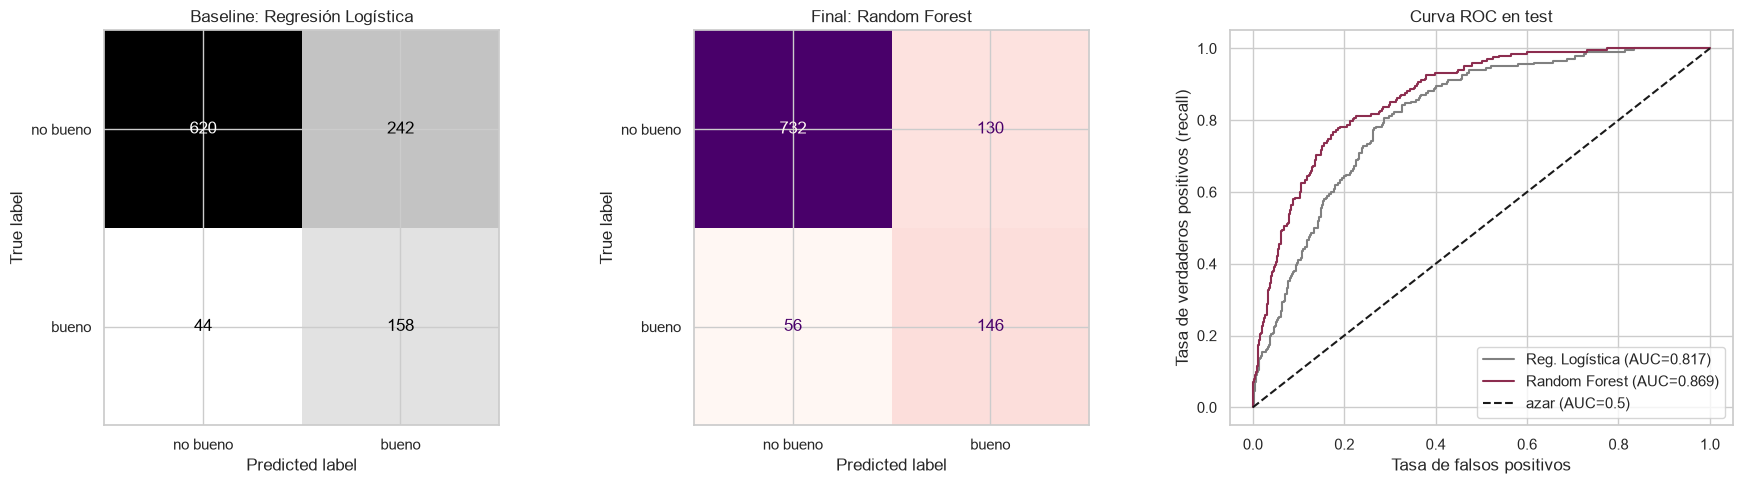

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_base), display_labels=["no bueno", "bueno"]).plot(ax=ax[0], cmap="Greys", colorbar=False)
ax[0].set_title("Baseline: Regresión Logística")
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["no bueno", "bueno"]).plot(ax=ax[1], cmap="RdPu", colorbar=False)
ax[1].set_title(f"Final: {mejor_nombre}")
for nombre, p, col in [("Reg. Logística", proba_base, "gray"), (mejor_nombre, proba_test, "#8c2d4f")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[2].plot(fpr, tpr, color=col, label=f"{nombre} (AUC={roc_auc_score(y_test, p):.3f})")
ax[2].plot([0, 1], [0, 1], "k--", label="azar (AUC=0.5)")
ax[2].set_xlabel("Tasa de falsos positivos"); ax[2].set_ylabel("Tasa de verdaderos positivos (recall)")
ax[2].set_title("Curva ROC en test"); ax[2].legend(loc="lower right")
plt.tight_layout(); guardar("09_evaluacion_test"); plt.show()

### 8.1 ¿Qué variables usa el modelo? (importancia de características)

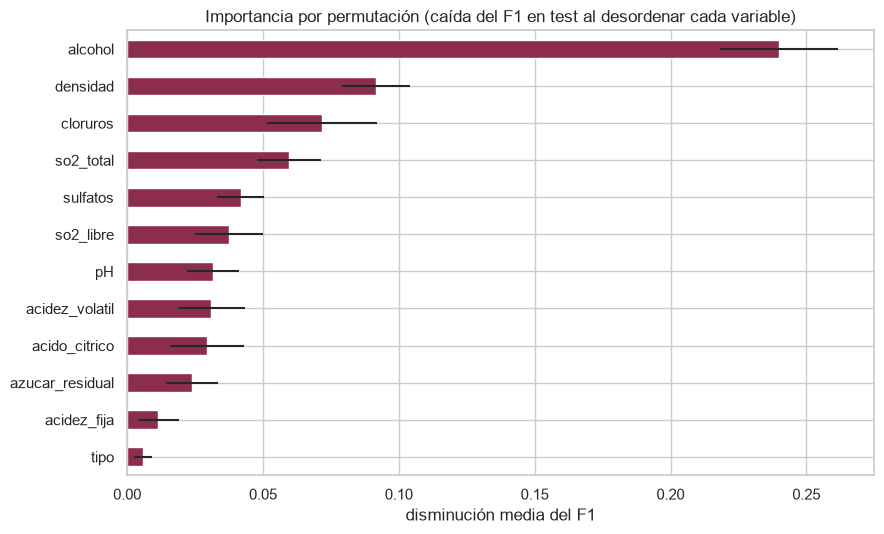

alcohol            0.2400
densidad           0.0915
cloruros           0.0716
so2_total          0.0596
sulfatos           0.0417
so2_libre          0.0375
pH                 0.0317
acidez_volatil     0.0309
acido_citrico      0.0295
azucar_residual    0.0238
acidez_fija        0.0114
tipo               0.0057
dtype: float64

In [ ]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(modelo_final, X_test, y_test, scoring="f1", n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()

plt.figure(figsize=(9, 5.5))
imp.plot.barh(color="#8c2d4f", xerr=perm.importances_std[np.argsort(perm.importances_mean)])
plt.title("Importancia por permutación (caída del F1 en test al desordenar cada variable)")
plt.xlabel("disminución media del F1"); plt.tight_layout(); guardar("10_importancia"); plt.show()
imp.sort_values(ascending=False).round(4)

La **importancia por permutación** mide cuánto empeora el F1 si se "desordena" una variable al azar: cuanto más cae, más depende el modelo de ella. Funciona para cualquier modelo (no solo Random Forest) y se calcula sobre datos no vistos.

## FASE 9. Bonus no supervisado: ¿K-Means descubre solo los tintos y los blancos?

Para aplicar también aprendizaje **no supervisado**, se oculta la etiqueta `tipo` y se le pide a K-Means que agrupe los vinos solo con sus 11 mediciones químicas (estandarizadas, porque K-Means usa distancias). Luego se compara cada grupo con el tipo real.

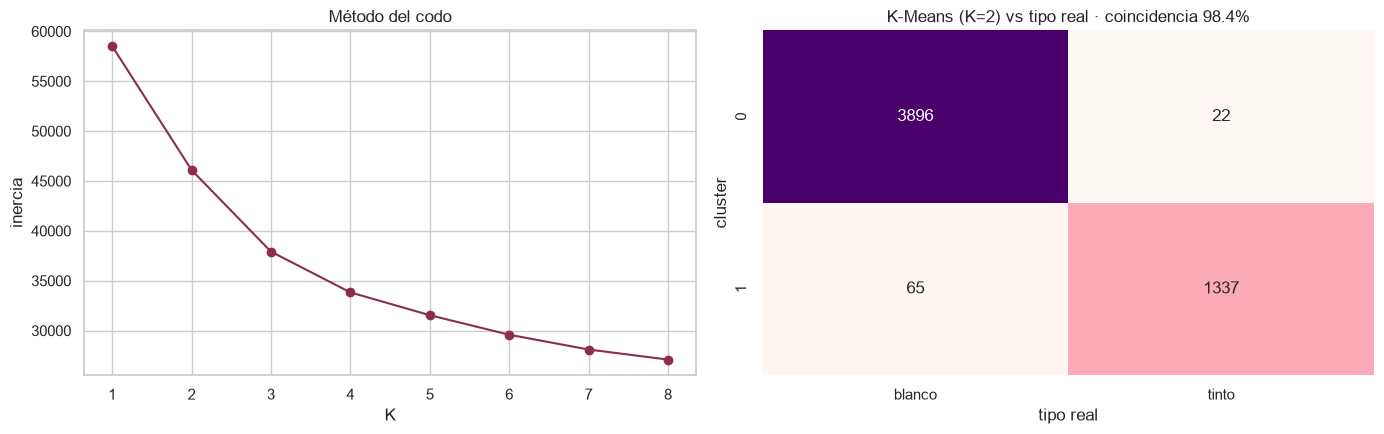

Coincidencia de clusters con el tipo real: 98.4%  |  Adjusted Rand Index: 0.932


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

Xq = StandardScaler().fit_transform(vinos[features])
inercias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xq).inertia_ for k in range(1, 9)]

km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xq)
tabla_km = pd.crosstab(km.labels_, vinos["tipo"].map({0: "tinto", 1: "blanco"}), rownames=["cluster"], colnames=["tipo real"])
ari = adjusted_rand_score(vinos["tipo"], km.labels_)
aciertos = tabla_km.max(axis=1).sum() / len(vinos)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(range(1, 9), inercias, "o-", color="#8c2d4f"); ax[0].set_xlabel("K"); ax[0].set_ylabel("inercia")
ax[0].set_title("Método del codo")
sns.heatmap(tabla_km, annot=True, fmt="d", cmap="RdPu", ax=ax[1], cbar=False)
ax[1].set_title(f"K-Means (K=2) vs tipo real · coincidencia {aciertos:.1%}")
plt.tight_layout(); guardar("11_kmeans"); plt.show()
print(f"Coincidencia de clusters con el tipo real: {aciertos:.1%}  |  Adjusted Rand Index: {ari:.3f}")

Sin conocer ninguna etiqueta, K-Means separa casi perfectamente tintos de blancos: la química de ambos tipos es muy distinta (lo que ya se intuía en los histogramas del EDA). Es un buen ejemplo de cómo el aprendizaje no supervisado **encuentra estructura oculta** en los datos.

## FASE 10. Inferencia: predicción para vinos nuevos

In [ ]:
nuevos = pd.DataFrame([
    # tinto con alcohol alto y poca acidez volátil
    {"acidez_fija": 7.5, "acidez_volatil": 0.35, "acido_citrico": 0.45, "azucar_residual": 2.2, "cloruros": 0.065,
     "so2_libre": 12, "so2_total": 35, "densidad": 0.9952, "pH": 3.30, "sulfatos": 0.80, "alcohol": 12.8, "tipo": 0},
    # tinto con alcohol bajo y acidez volátil alta
    {"acidez_fija": 7.8, "acidez_volatil": 0.85, "acido_citrico": 0.05, "azucar_residual": 2.0, "cloruros": 0.095,
     "so2_libre": 10, "so2_total": 45, "densidad": 0.9975, "pH": 3.40, "sulfatos": 0.55, "alcohol": 9.4, "tipo": 0},
    # blanco con alcohol alto
    {"acidez_fija": 6.5, "acidez_volatil": 0.25, "acido_citrico": 0.32, "azucar_residual": 3.0, "cloruros": 0.032,
     "so2_libre": 35, "so2_total": 120, "densidad": 0.9905, "pH": 3.20, "sulfatos": 0.50, "alcohol": 12.5, "tipo": 1},
])[X.columns]
p = modelo_final.predict_proba(nuevos)[:, 1]
pd.DataFrame({"descripción": ["Tinto, 12.8% alc., baja acidez volátil", "Tinto, 9.4% alc., acidez volátil alta",
                              "Blanco, 12.5% alc."],
              "prob. de ser bueno": p.round(3),
              "predicción": np.where(p >= umbral, "BUENO", "no bueno")})

,descripción,prob. de ser bueno,predicción
0,"Tinto, 12.8% alc., baja acidez volátil",0.820,BUENO
1,"Tinto, 9.4% alc., acidez volátil alta",0.021,no bueno
2,"Blanco, 12.5% alc.",0.836,BUENO


Los valores de los vinos nuevos están **dentro del rango de los datos de entrenamiento** (ver `describe()`), así que la predicción es confiable en ese sentido; un modelo no debería usarse para extrapolar fuera del rango que conoce (lección de la actividad del maratón).

## Conclusiones
1. **El EDA fue decisivo:** detectó 1.177 duplicados (que habrían inflado las métricas por data leakage), el desbalance de clases (que invalida la accuracy) y las relaciones no lineales que justificaron pasar a modelos de ensemble.
2. **Baseline → modelo final:** partiendo de un Dummy (F1 = 0) y de una Regresión Logística balanceada, el modelo de ensemble ajustado mejoró claramente el F1 y el ROC-AUC en el conjunto de test.
3. **Lo que más pesa en la calidad:** el **alcohol**, la **acidez volátil** y los **sulfatos/SO₂ libre**: información accionable para el enólogo.
4. **Limitaciones:** la nota es subjetiva (mediana de catadores), faltan variables como uva, precio, añada o bodega, y todos los vinos son de una sola denominación portuguesa (*Vinho Verde*), por lo que el modelo no debería aplicarse a vinos de otras regiones sin reentrenarlo.
5. **Próximos pasos:** probar XGBoost/LightGBM, modelar la nota completa como regresión u ordinal, y agregar más datos de otras regiones (por ejemplo, vinos argentinos).

**Referencia del dataset:** P. Cortez, A. Cerdeira, F. Almeida, T. Matos y J. Reis, "Modeling wine preferences by data mining from physicochemical properties", *Decision Support Systems*, vol. 47, n.º 4, pp. 547–553, 2009. Disponible en UCI Machine Learning Repository.